In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

In [2]:
df = pd.read_csv("diabetes.csv")
def describe(df):
    print("Shape: ", df.shape)
    print("\nFirst 5 rows:");  print(df.head())
    print("\nLast 5 rows:");   print(df.tail())
    print("\nInfo:");          df.info()
    print("\nStatistics:");    print(df.describe())
    print("\nMissing values:"); print(df.isnull().sum())
describe(df)
for c in ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]:   # 0 is impossible -> missing
    df[c] = df[c].replace(0, df[c].median())

Shape:  (768, 9)

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  

Last 5 rows:
     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72             23      112  26.2   
766            1      126             60              0  

In [3]:
X, y = df.drop(columns=["Outcome"]), df["Outcome"]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
sc = StandardScaler(); X_train = sc.fit_transform(X_train); X_test = sc.transform(X_test)

Confusion Matrix:
 [[80 20]
 [27 27]]
Accuracy  : 0.6948051948051948
Error rate: 0.30519480519480524
Precision : 0.574468085106383
Recall    : 0.5


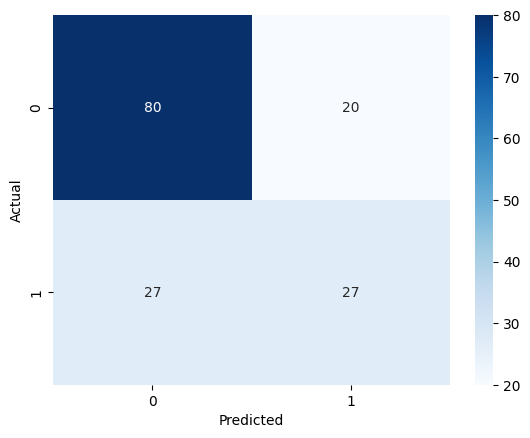

In [4]:
knn = KNeighborsClassifier(n_neighbors=7).fit(X_train,y_train)
pred = knn.predict(X_test)
cm = confusion_matrix(y_test,pred); print("Confusion Matrix:\n",cm)
acc = accuracy_score(y_test,pred)
print("Accuracy  :",acc); print("Error rate:",1-acc)
print("Precision :",precision_score(y_test,pred)); print("Recall    :",recall_score(y_test,pred))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

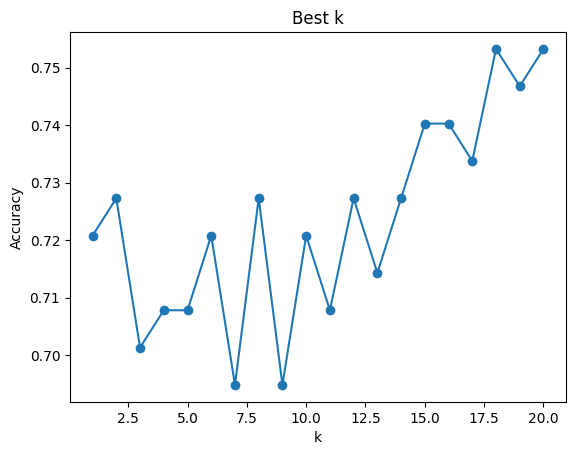

Best k: 18


In [5]:
ks = range(1,21)
accs = [accuracy_score(y_test,KNeighborsClassifier(n_neighbors=k).fit(X_train,y_train).predict(X_test)) for k in ks]
plt.plot(ks,accs,marker="o"); plt.xlabel("k"); plt.ylabel("Accuracy"); plt.title("Best k"); plt.show()
print("Best k:", ks[int(np.argmax(accs))])